In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 54.7 MB/s  0:00:01


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [3]:
df = pd.read_csv("diabetes_patients_10000_full.csv")

In [4]:
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [5]:
df.shape

(10000, 10)

In [6]:
df.columns

Index(['Patient_ID', 'Age', 'Gender', 'Blood_Sugar_Level', 'Creatinine', 'BMI',
       'Urea', 'Cholesterol', 'HbA1c', 'Class'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   object 
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  object 
dtypes: float64(7), int64(1), object(2)
memory usage: 781.4+ KB


In [8]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,10000.00000,9986.000000,9947.000000,9944.000000,9949.000000,9949.000000,9968.000000,10000.000000
mean,5000.50000,49.957240,169.255454,1.100253,26.746959,35.121520,225.311196,7.503780
std,2886.89568,17.630097,46.059059,0.286964,4.787215,11.829985,43.806703,1.743745
min,1.00000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2500.75000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5000.50000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7500.25000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.00000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()
if "Patient_ID" in df.columns:
    df = df.drop(columns="Patient_ID")

In [11]:
df.isnull().sum()

,0
Age,14
Gender,40
Blood_Sugar_Level,53
Creatinine,56
BMI,51
Urea,51
Cholesterol,32
HbA1c,0
Class,0


In [12]:
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [13]:
df.isnull().sum()

,0
Age,0
Gender,0
Blood_Sugar_Level,0
Creatinine,0
BMI,0
Urea,0
Cholesterol,0
HbA1c,0
Class,0


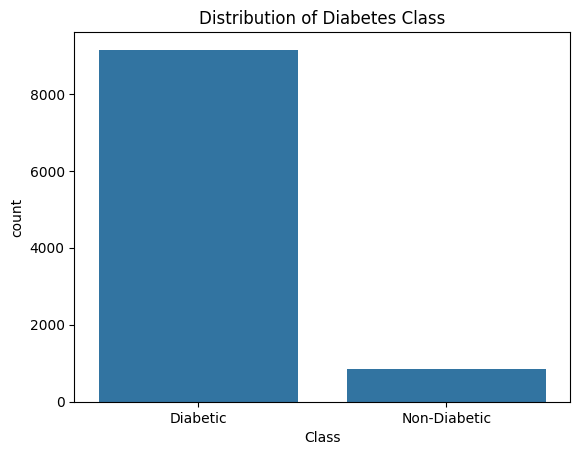

In [14]:
sns.countplot(x="Class", data=df)
plt.title("Distribution of Diabetes Class")
plt.show()

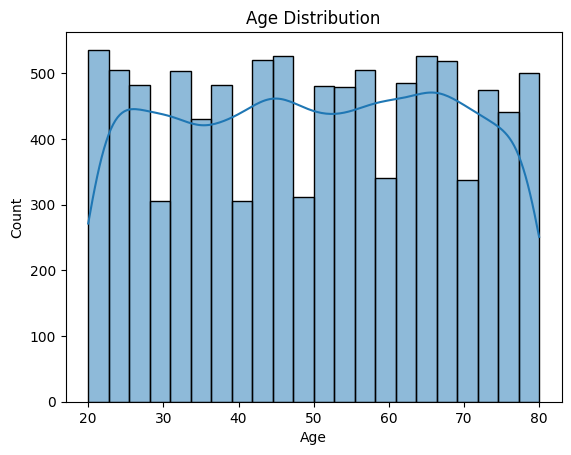

In [15]:
sns.histplot(df["Age"], kde=True)
plt.title("Age Distribution")
plt.show()

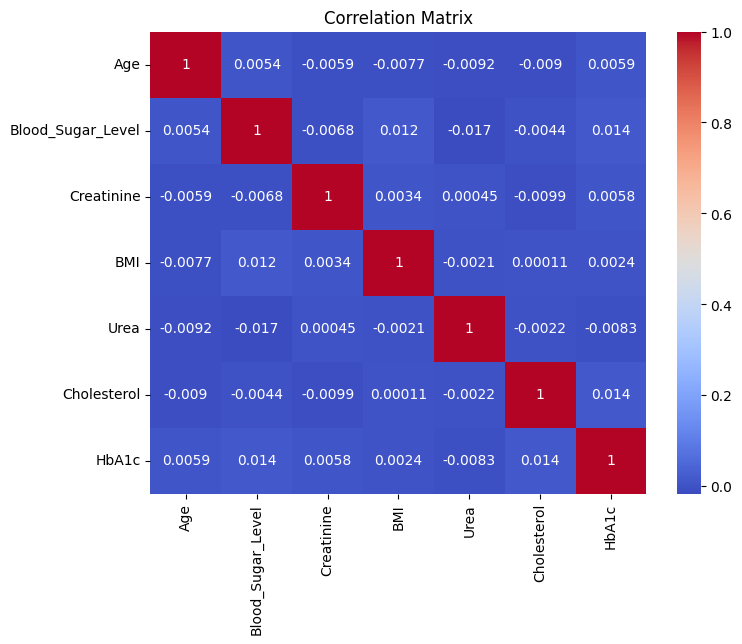

In [16]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [17]:
df["Gender"] = df["Gender"].map({"Female": 0, "Male": 1})
df["Class"] = df["Class"].map({"Non-Diabetic": 0, "Diabetic": 1})

In [18]:
X = df.drop(columns="Class")
y = df["Class"]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [22]:
num_cols = ["Age", "Blood_Sugar_Level", "Creatinine", "BMI", "Urea", "Cholesterol", "HbA1c"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [23]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)

In [24]:
results = []

In [25]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    log_model = LogisticRegression(max_iter=1000)
    log_model.fit(X_tr, y_tr)
    y_pred = log_model.predict(X_test)
    results.append({
        'Model': "Logistic Regression",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [26]:
log_cw = LogisticRegression(max_iter=1000, class_weight='balanced')
log_cw.fit(X_train, y_train)
y_pred = log_cw.predict(X_test)
results.append({
    'Model': "Logistic Regression",
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred, zero_division=0)
})

In [27]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    knn_model = KNeighborsClassifier(n_neighbors=5)
    knn_model.fit(X_tr, y_tr)
    y_pred = knn_model.predict(X_test)
    results.append({
        'Model': "KNN",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [28]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    nb_model = GaussianNB()
    nb_model.fit(X_tr, y_tr)
    y_pred = nb_model.predict(X_test)
    results.append({
        'Model': "Naive Bayes",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [29]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    svm_model = SVC()
    svm_model.fit(X_tr, y_tr)
    y_pred = svm_model.predict(X_test)
    results.append({
        'Model': "SVM",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [30]:
svm_cw = SVC(class_weight='balanced')
svm_cw.fit(X_train, y_train)
y_pred = svm_cw.predict(X_test)
results.append({
    'Model': "SVM",
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred, zero_division=0)
})

In [31]:
dt_params = dict(
    criterion='gini',
    random_state=100,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    min_impurity_decrease=0.0,
    ccp_alpha=0.0
)

In [32]:
for method_name, X_tr, y_tr in [("Normal Data", X_train, y_train), ("SMOTE Over Sampling", X_train_smote, y_train_smote), ("Random Under Sampling", X_train_rus, y_train_rus)]:
    dt_model = DecisionTreeClassifier(**dt_params)
    dt_model.fit(X_tr, y_tr)
    y_pred = dt_model.predict(X_test)
    results.append({
        'Model': "Decision Tree",
        'Method': method_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    })

In [33]:
dt_cw = DecisionTreeClassifier(**dt_params, class_weight='balanced')
dt_cw.fit(X_train, y_train)
y_pred = dt_cw.predict(X_test)
results.append({
    'Model': "Decision Tree",
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred, zero_division=0)
})

In [34]:
results_df = pd.DataFrame(results).set_index(['Model', 'Method'])
print(results_df.round(3))

                                           Accuracy  Precision  Recall  \
Model               Method                                               
Logistic Regression Normal Data               0.970      0.978   0.989   
                    SMOTE Over Sampling       0.949      0.995   0.949   
                    Random Under Sampling     0.931      0.996   0.928   
                    Class Weight Balanced     0.942      0.997   0.939   
KNN                 Normal Data               0.966      0.975   0.988   
                    SMOTE Over Sampling       0.931      0.998   0.927   
                    Random Under Sampling     0.858      0.999   0.845   
Naive Bayes         Normal Data               0.986      0.984   1.000   
                    SMOTE Over Sampling       0.976      0.999   0.974   
                    Random Under Sampling     0.963      0.999   0.960   
SVM                 Normal Data               0.978      0.984   0.992   
                    SMOTE Over Samplin

In [35]:
from sklearn.tree import DecisionTreeClassifier

dt_feat_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_feat_model.fit(X_train, y_train)

importances = pd.Series(dt_feat_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

selected_features = importances.index[:10]
print("Top 10 Important Features:", selected_features.tolist())

selected_features = importances.nlargest(10)
print("Decision Tree Selected Features (Scores):", selected_features.tolist())

Top 10 Important Features: ['Blood_Sugar_Level', 'HbA1c', 'Age', 'Gender', 'Creatinine', 'BMI', 'Urea', 'Cholesterol']
Decision Tree Selected Features (Scores): [0.7305775680803346, 0.2689257545527536, 0.0004966773669119328, 0.0, 0.0, 0.0, 0.0, 0.0]


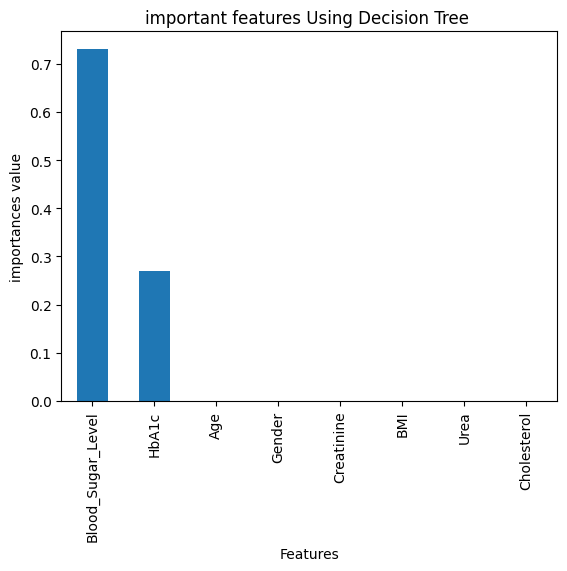

In [36]:
importances.plot(kind='bar')
plt.title("important features Using Decision Tree ")
plt.xlabel("Features")
plt.ylabel("importances value")
plt.show()

In [37]:
from sklearn.model_selection import GridSearchCV

grid_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=5, scoring='f1')
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1 Score:", grid.best_score_)

Best Parameters: {'C': 10, 'kernel': 'rbf'}
Best CV F1 Score: 0.9915991484766693


In [38]:
best_model = grid.best_estimator_

In [39]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[ 131   40]
 [  20 1809]]


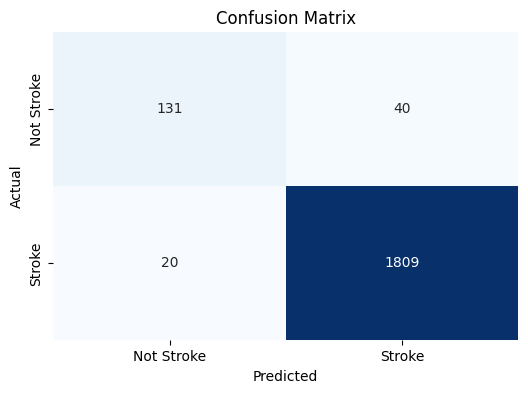


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.77      0.81       171
      Stroke       0.98      0.99      0.98      1829

    accuracy                           0.97      2000
   macro avg       0.92      0.88      0.90      2000
weighted avg       0.97      0.97      0.97      2000

ROC-AUC: 0.9902768585396423


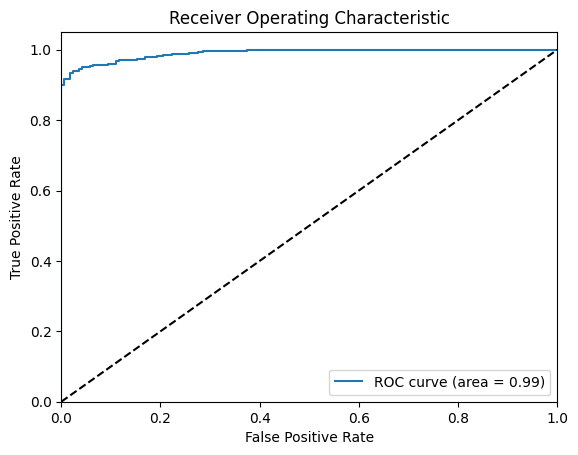

PR AUC: 0.9990875568536371


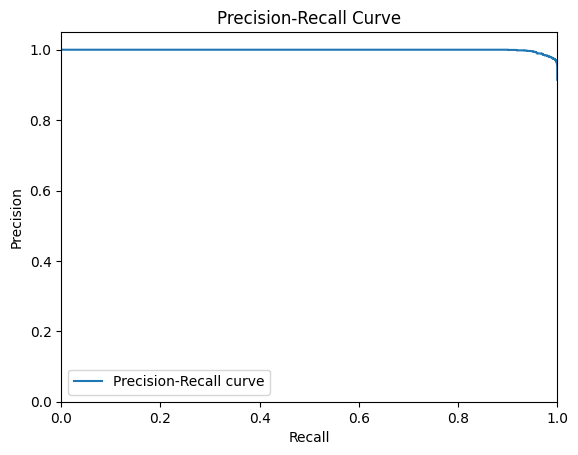

  8%|▊         | 1/13 [00:00<00:05,  2.16it/s]


Confusion Matrix:
 [[ 124   47]
 [  22 1807]]


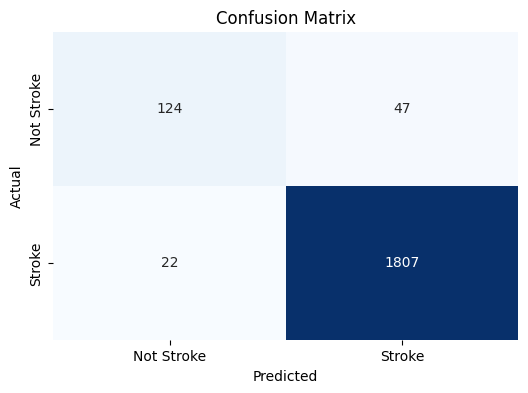


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.73      0.78       171
      Stroke       0.97      0.99      0.98      1829

    accuracy                           0.97      2000
   macro avg       0.91      0.86      0.88      2000
weighted avg       0.96      0.97      0.96      2000

ROC-AUC: 0.9798886682717365


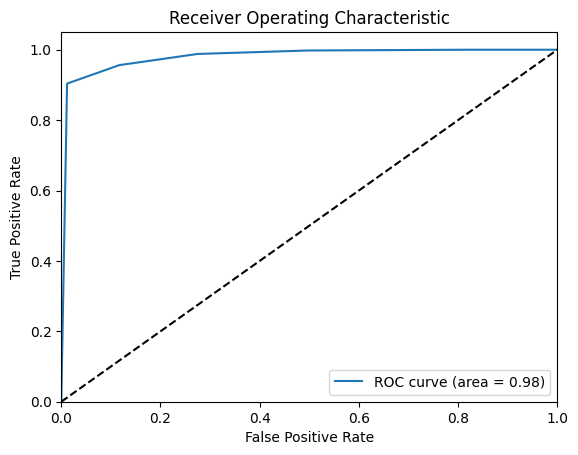

PR AUC: 0.9969170410590283


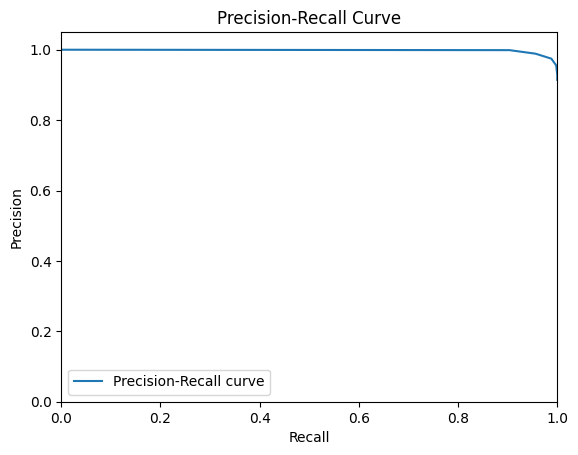

 15%|█▌        | 2/13 [00:01<00:07,  1.48it/s]


Confusion Matrix:
 [[ 141   30]
 [  15 1814]]


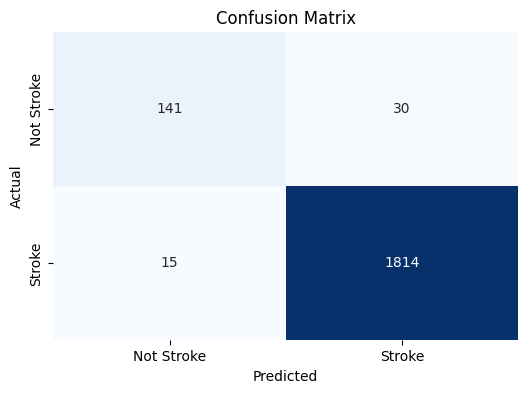


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.82      0.86       171
      Stroke       0.98      0.99      0.99      1829

    accuracy                           0.98      2000
   macro avg       0.94      0.91      0.93      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.9944557950370734


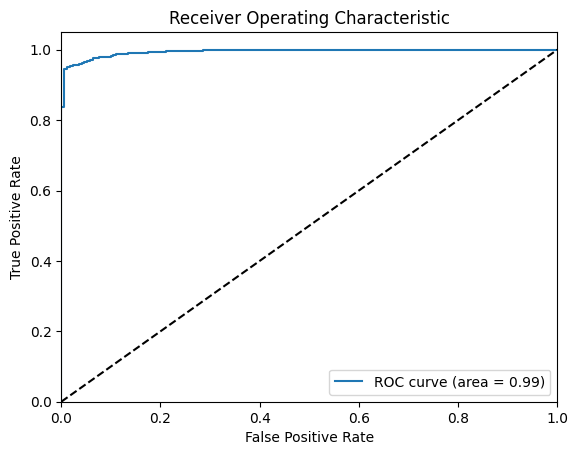

PR AUC: 0.9994740416392193


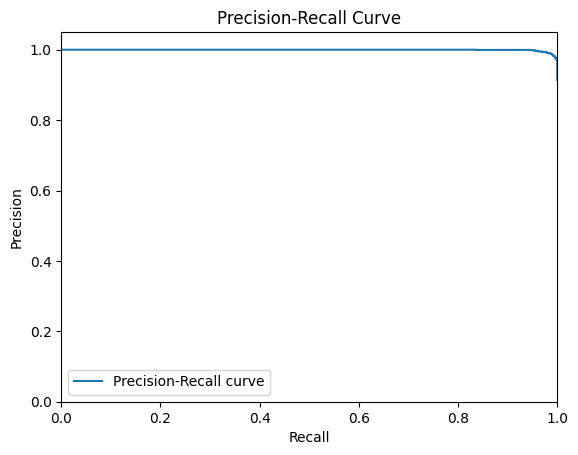

 23%|██▎       | 3/13 [00:03<00:13,  1.31s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


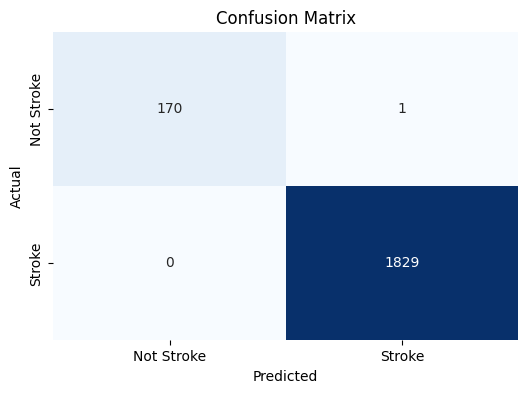


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.9970760233918129


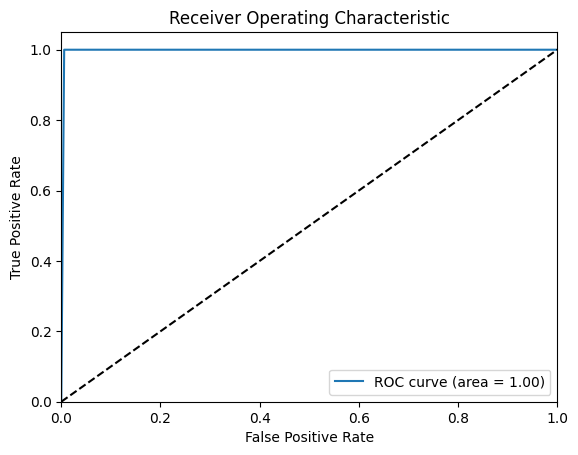

PR AUC: 0.9994535519125683


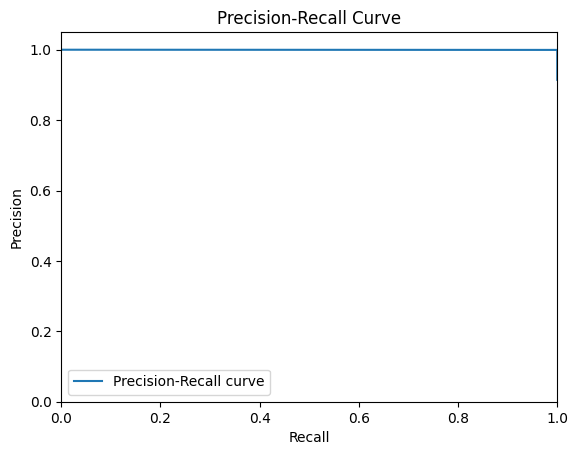

 31%|███       | 4/13 [00:03<00:08,  1.03it/s]


Confusion Matrix:
 [[ 142   29]
 [   0 1829]]


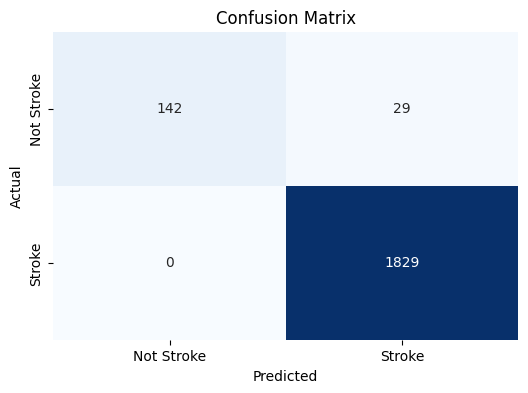


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.83      0.91       171
      Stroke       0.98      1.00      0.99      1829

    accuracy                           0.99      2000
   macro avg       0.99      0.92      0.95      2000
weighted avg       0.99      0.99      0.98      2000

ROC-AUC: 0.9985196269331977


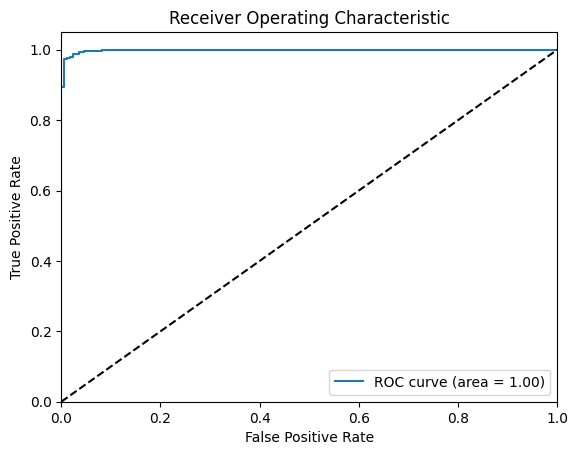

PR AUC: 0.9998583695993937


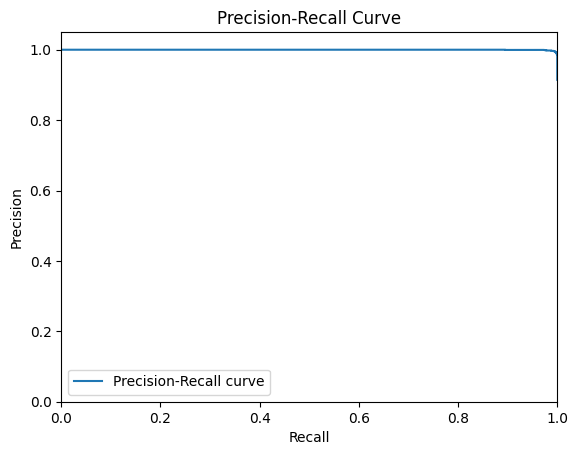

 38%|███▊      | 5/13 [00:04<00:06,  1.30it/s]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


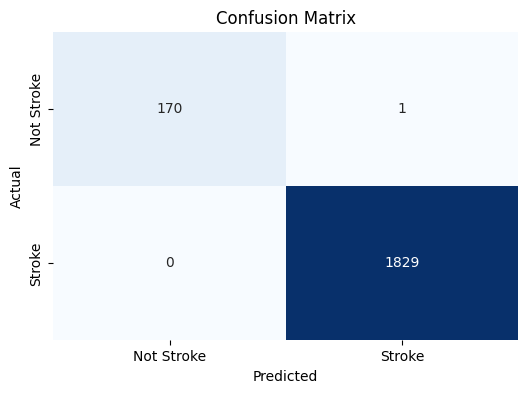


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


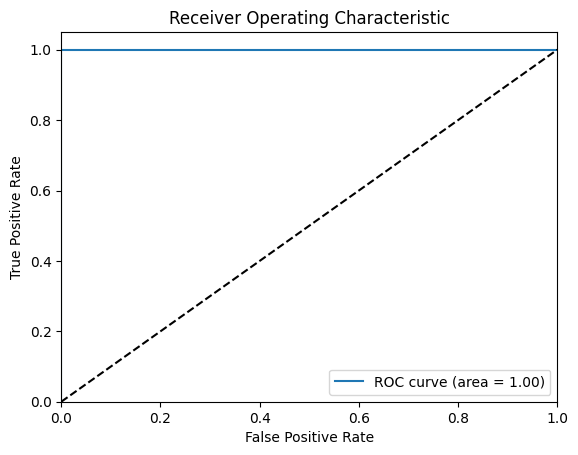

PR AUC: 1.0


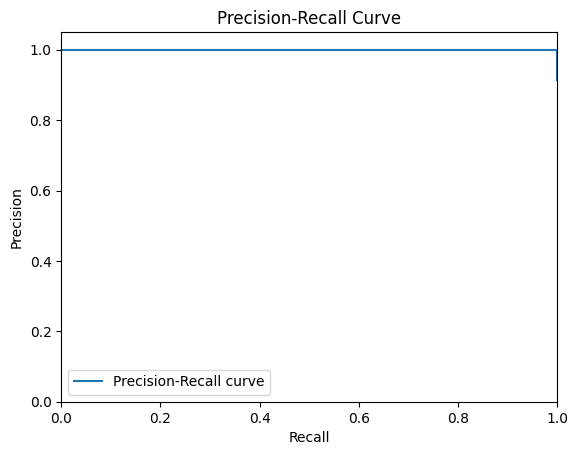

 46%|████▌     | 6/13 [00:05<00:05,  1.23it/s]


Confusion Matrix:
 [[ 147   24]
 [   1 1828]]


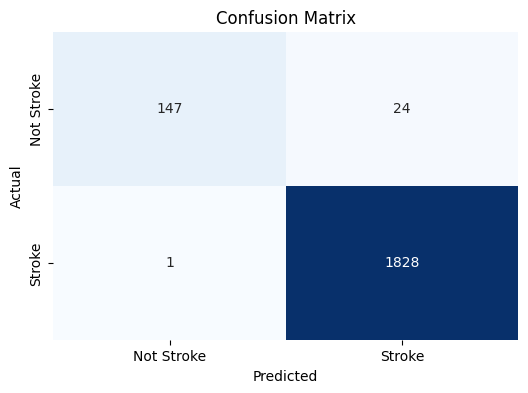


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.99      0.86      0.92       171
      Stroke       0.99      1.00      0.99      1829

    accuracy                           0.99      2000
   macro avg       0.99      0.93      0.96      2000
weighted avg       0.99      0.99      0.99      2000

ROC-AUC: 0.9991878730907823


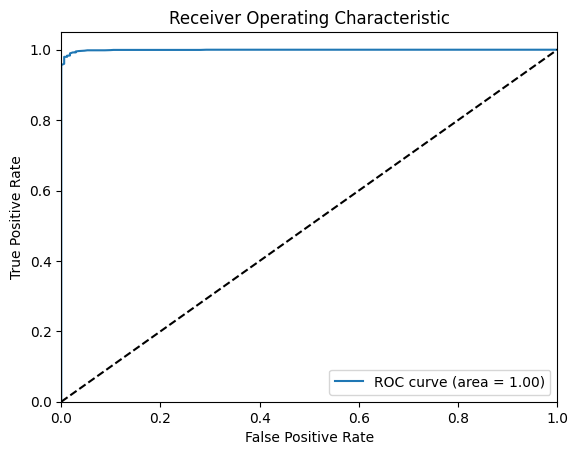

PR AUC: 0.9999203696787142


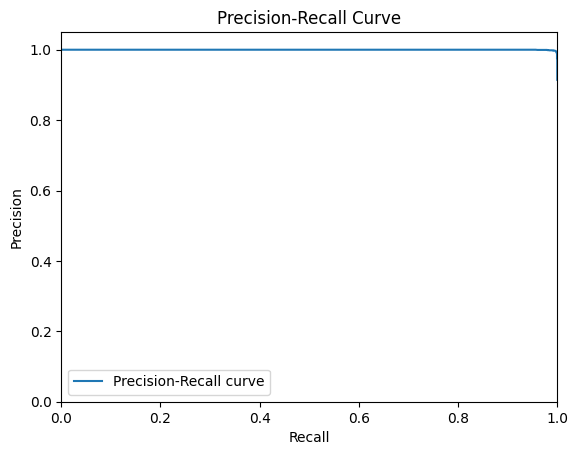

 54%|█████▍    | 7/13 [00:06<00:05,  1.18it/s]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


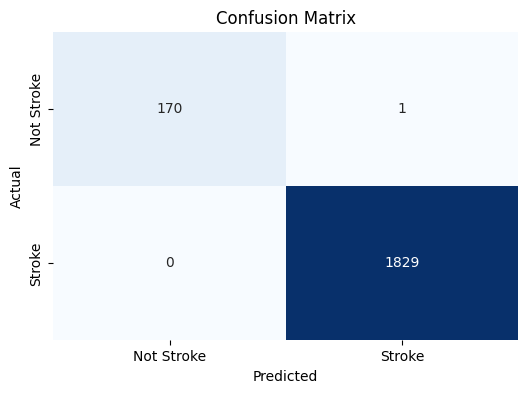


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


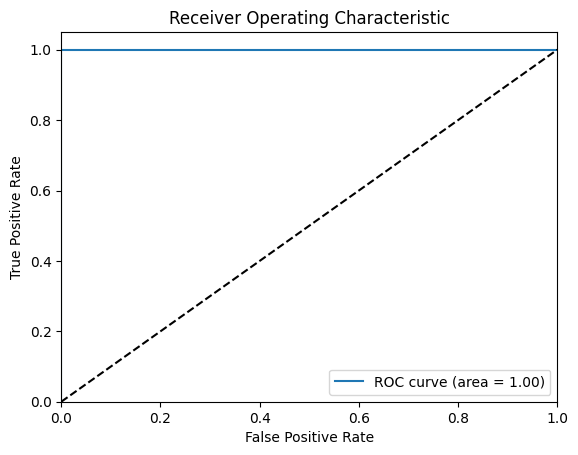

PR AUC: 1.0


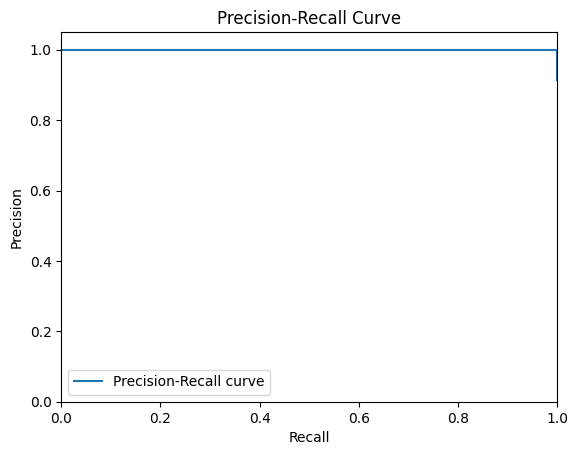

 62%|██████▏   | 8/13 [00:06<00:04,  1.20it/s]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


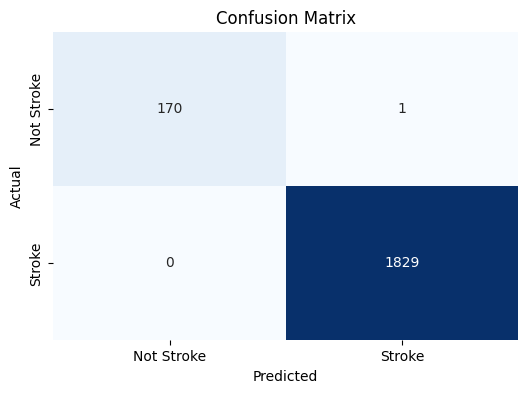


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


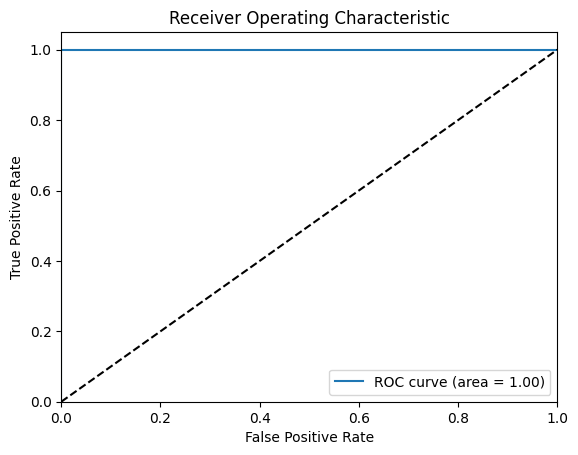

PR AUC: 1.0


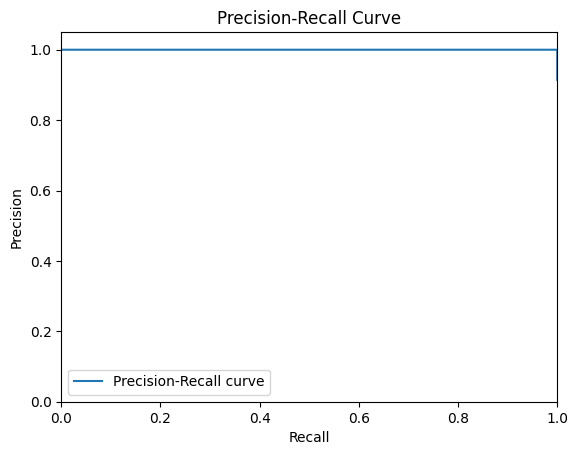

 69%|██████▉   | 9/13 [00:08<00:04,  1.06s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


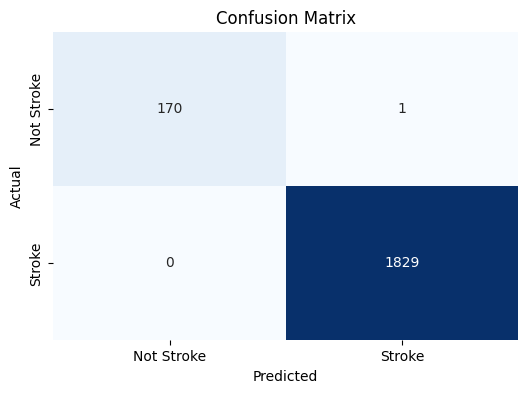


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


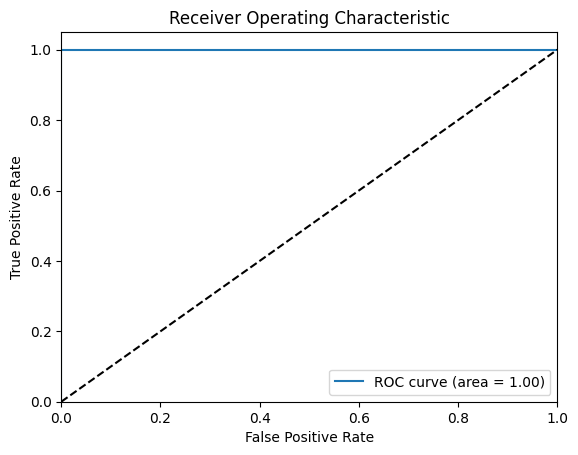

PR AUC: 1.0000000000000002


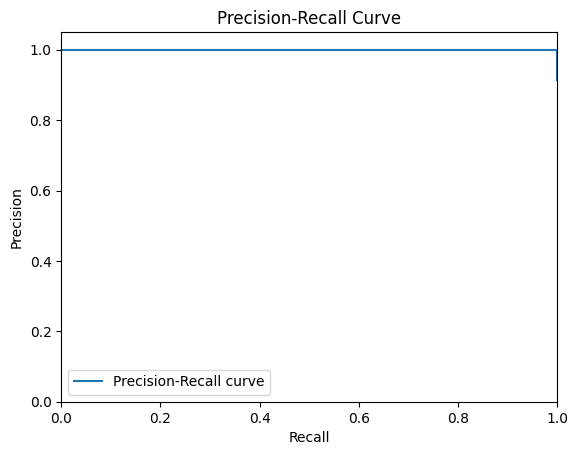

 77%|███████▋  | 10/13 [00:09<00:03,  1.02s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:24:37] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


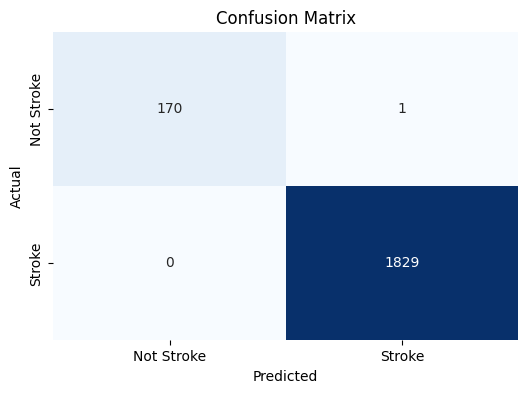


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


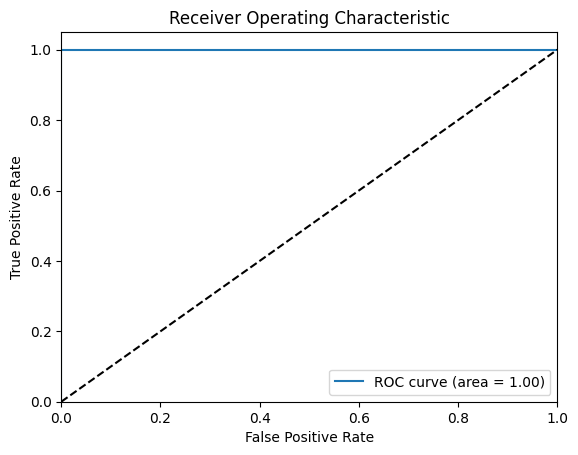

PR AUC: 0.9999999999999999


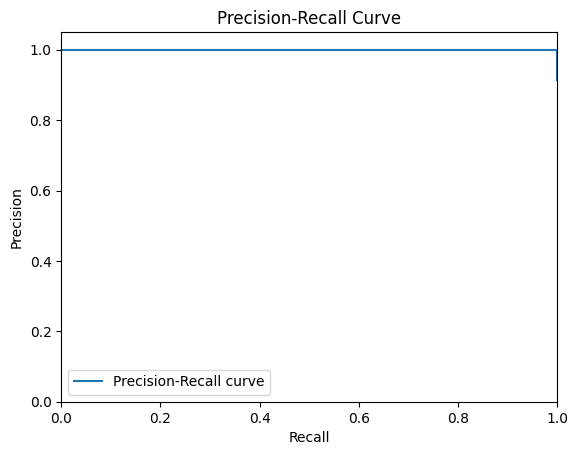

 85%|████████▍ | 11/13 [00:10<00:02,  1.14s/it]


Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


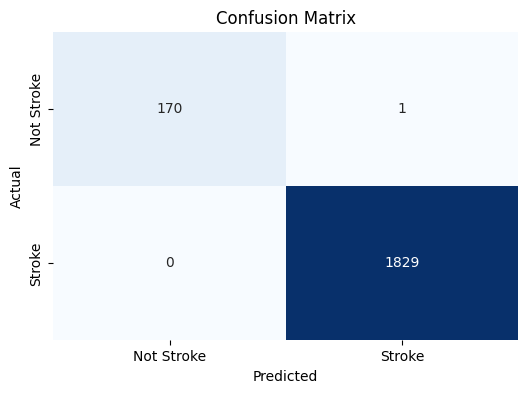


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


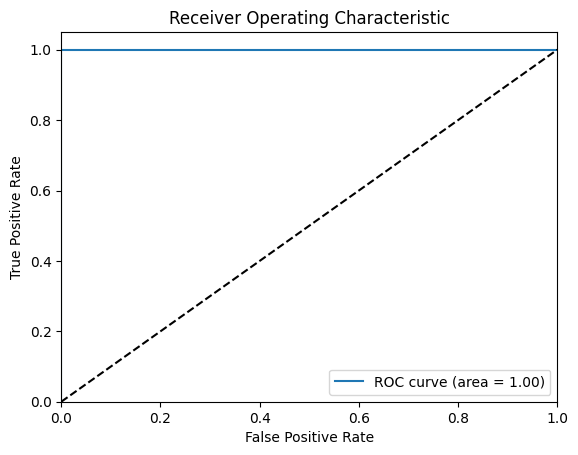

PR AUC: 1.0


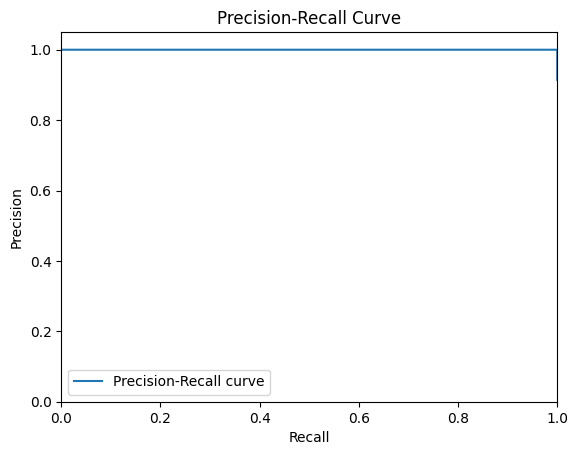

 92%|█████████▏| 12/13 [00:14<00:01,  1.91s/it]

[LightGBM] [Info] Number of positive: 7317, number of negative: 683
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003247 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 751
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.914625 -> initscore=2.371461
[LightGBM] [Info] Start training from score 2.371461
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

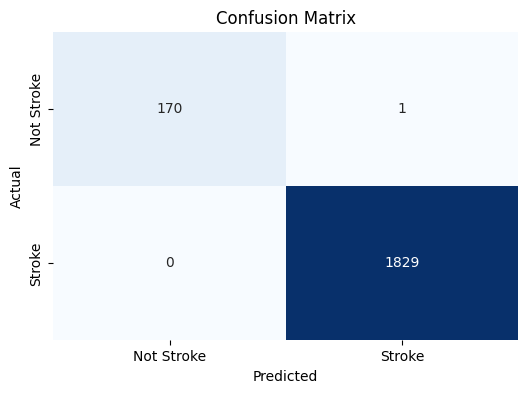


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.9999904079498911


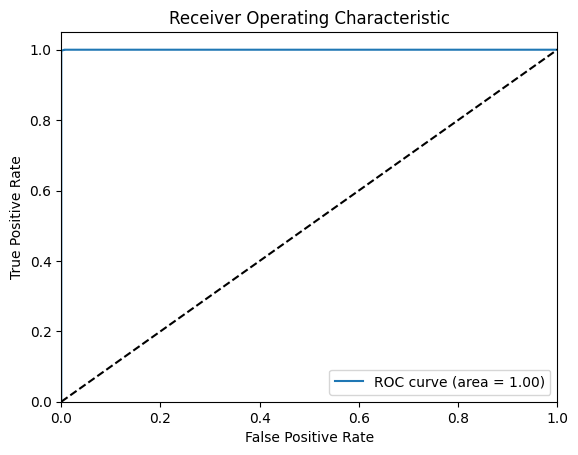

PR AUC: 0.9999985055027272


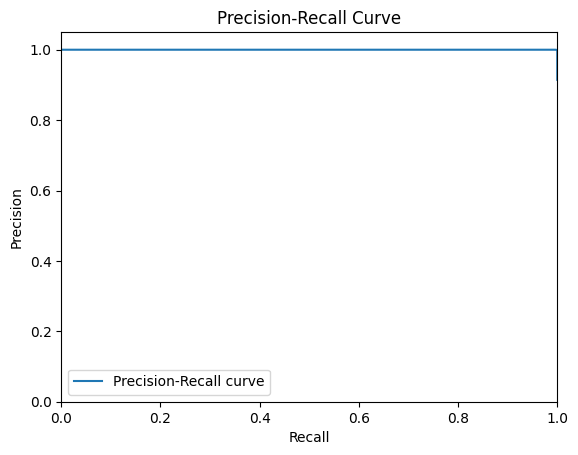

100%|██████████| 13/13 [00:15<00:00,  1.16s/it]


In [40]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:24:52] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


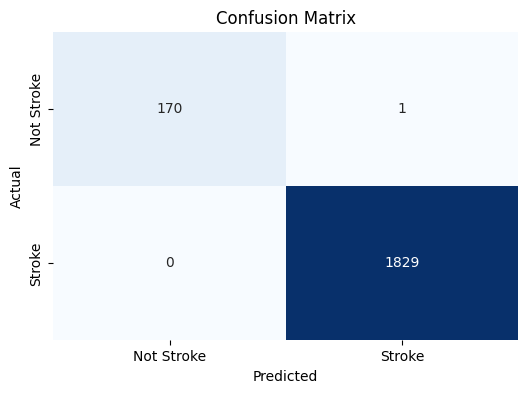


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 0.9997985669477137


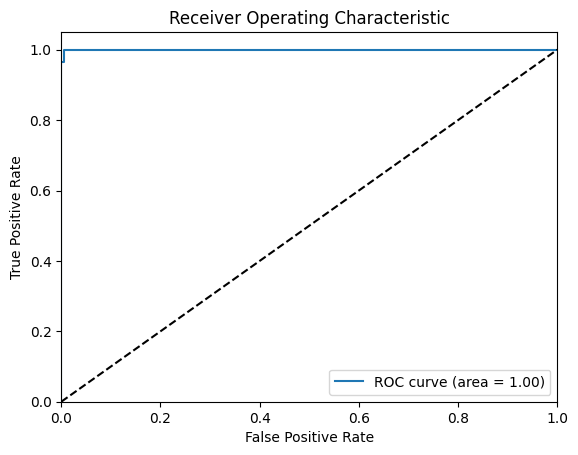

PR AUC: 0.9999808512663273


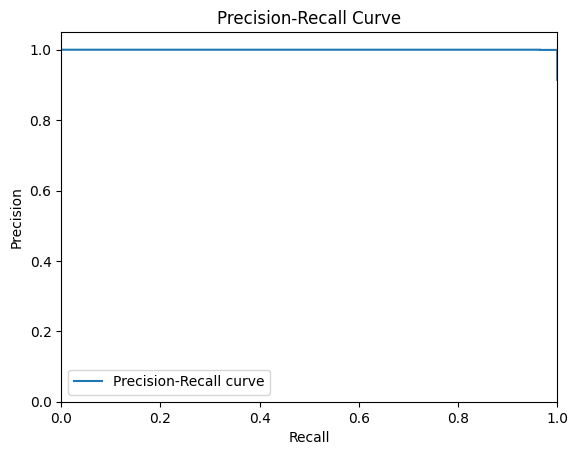

In [41]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [16:25:12] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[ 170    1]
 [   0 1829]]


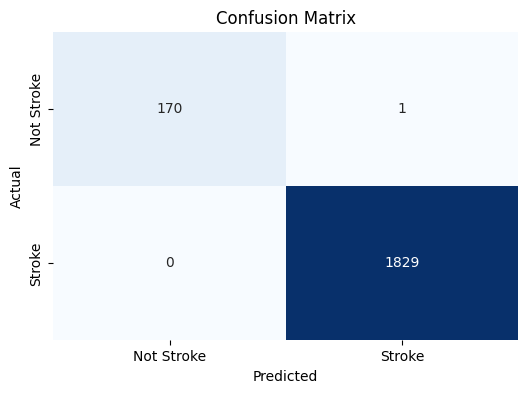


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       1.00      0.99      1.00       171
      Stroke       1.00      1.00      1.00      1829

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

ROC-AUC: 1.0


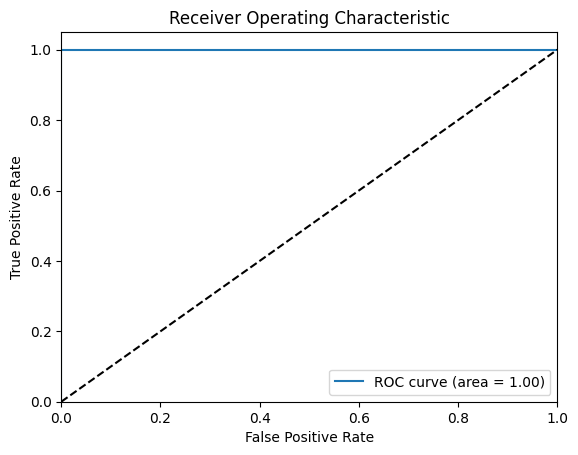

PR AUC: 1.0


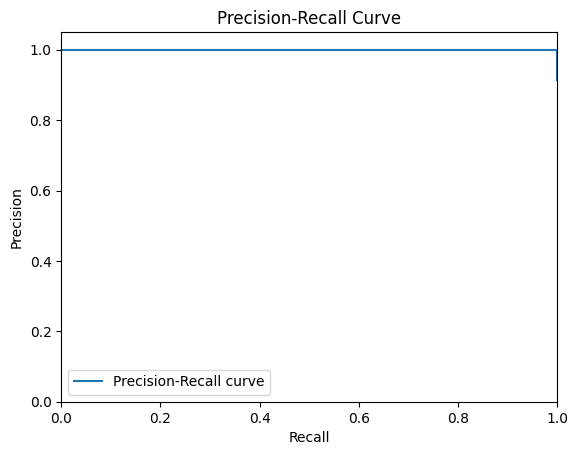

In [42]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [43]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [44]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Decision Tree,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,0.997076,0.999454
Random Forest,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
CatBoost,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
XGBoost,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
Hist Gradient Boosting,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
Gradient Boosting,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000
AdaBoost,0.999750,0.9995,0.999727,0.999454,1.000000,1.000000,0.999863,0.999727,0.998536,0.997076,1.000000,1.000000
Voting Classifier,0.999750,0.9995,0.999727,0.999454,1.000000,1.000000,0.999863,0.999727,0.998536,0.997076,0.999799,0.999981
LightGBM,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,0.999990,0.999999
Stacking Classifier,1.000000,0.9995,1.000000,0.999454,1.000000,1.000000,1.000000,0.999727,1.000000,0.997076,1.000000,1.000000


<Axes: >

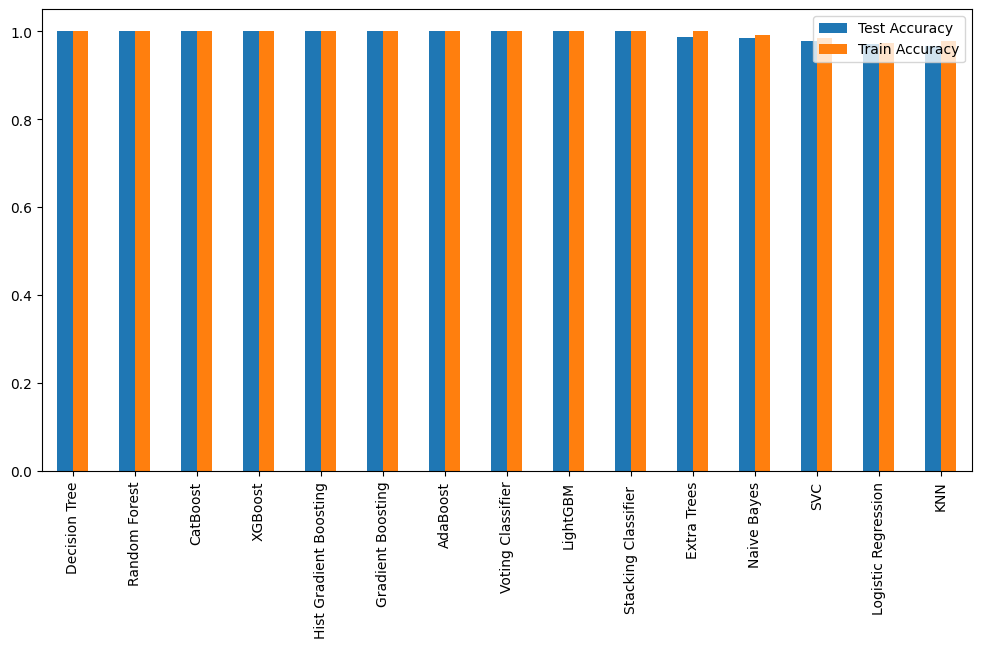

In [45]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

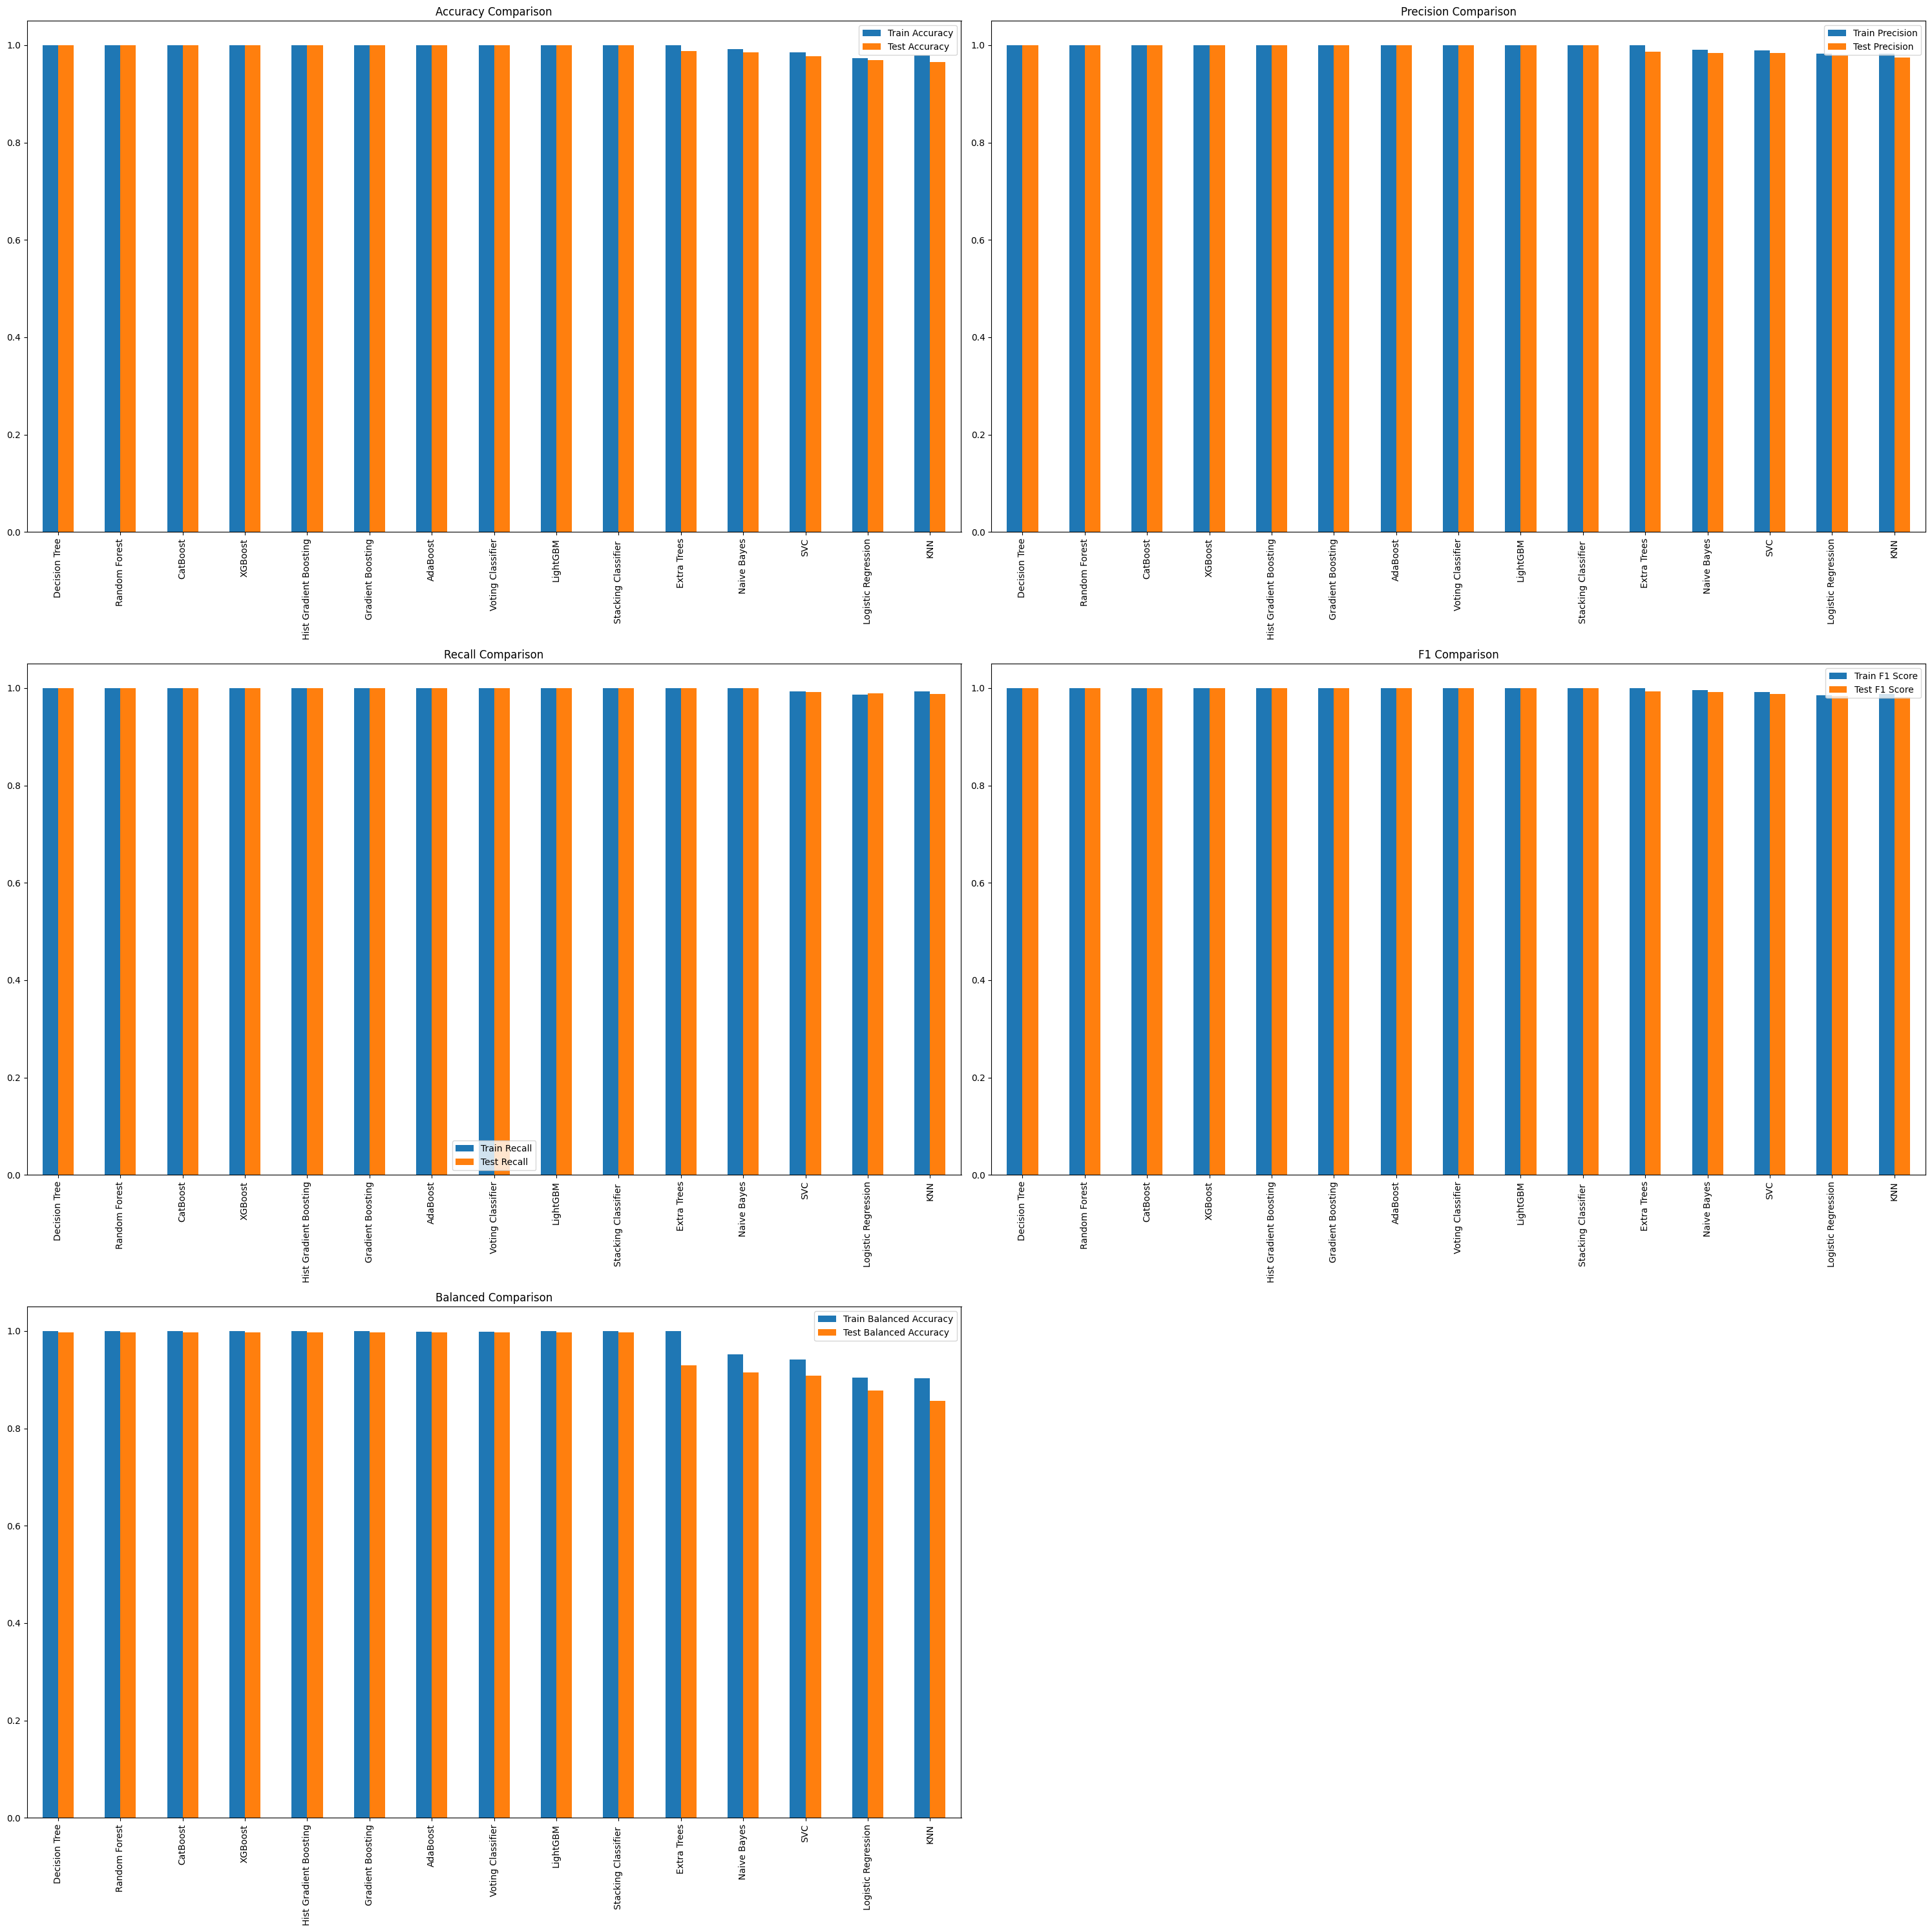

In [46]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

In [47]:
import gradio as gr

def predict_diabetes(age, gender, blood_sugar, creatinine, bmi, urea, cholesterol, hba1c):
    gender_val = 0 if gender == "Female" else 1

    row = pd.DataFrame([[
        age, gender_val, blood_sugar, creatinine, bmi, urea, cholesterol, hba1c
    ]], columns=X.columns).astype(float)

    row[num_cols] = scaler.transform(row[num_cols])

    prediction = best_model.predict(row)[0]
    return "Diabetic (مريض سكري)" if prediction == 1 else "Non-Diabetic (سليم)"

demo = gr.Interface(
    fn=predict_diabetes,
    inputs=[
        gr.Number(label="Age", value=45),
        gr.Dropdown(["Female", "Male"], label="Gender", value="Female"),
        gr.Number(label="Blood Sugar Level", value=110),
        gr.Number(label="Creatinine", value=1.0),
        gr.Number(label="BMI", value=25.0),
        gr.Number(label="Urea", value=30.0),
        gr.Number(label="Cholesterol", value=200.0),
        gr.Number(label="HbA1c", value=5.5),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Diabetes Prediction App",
    description="Enter patient medical details to predict whether the patient has diabetes.",
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2dc45097b6ae84a5e0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
